# Predicting the Ultimate Analysis of Coal from its Proximate Analysis
### A neural-network model for US and Indian coals

**Problem.** The *proximate analysis* of coal (moisture **M**, volatile matter **VM**, ash **A**, fixed carbon **FC**) is cheap and is measured routinely in every coal laboratory and power plant. The *ultimate analysis* (carbon **C**, hydrogen **H**, nitrogen **N**, sulphur **S**, oxygen **O**) needs an elemental analyser, but it is what combustion, gasification and emission calculations require. This notebook builds a model that predicts the ultimate analysis from the proximate analysis.

**Approach in brief**
1. Data: 7,800 coal samples that have *both* analyses: USGS COALQUAL (United States) and USGS–Geological Survey of India data (Indian bituminous coal and lignite) for training; the USGS World Coal Quality Inventory (1,239 samples, 60 countries) as an independent external test set.
2. Physics-based feature engineering: everything is converted to the **dry, ash-free (daf)** basis, where the composition of the organic coal substance depends mainly on coal rank. This makes coals from different countries — and data reported on different bases (as-received in the US, air-dried in India) — comparable.
3. Models compared: linear regression, quadratic regression, gradient boosting, a single neural network and an **ensemble of neural networks** (multilayer perceptrons), blended with a quadratic regression.
4. Honest validation: Indian accuracy is measured on **whole mines/coalfield blocks the model never saw** (leave-one-site-out), US accuracy on whole held-out sample groups, and generalisation on 60 countries that are not in the training data at all.
5. Oxygen is computed **by difference** so the result is physically consistent: C + H + N + S + O + M + Ash = 100 %.
6. The final model is exported to `model/coal_model.json`, which the deployed web app uses.

In [1]:
import json, os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from joblib import Parallel, delayed
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import r2_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

DATA_DIR = "data"          # folder with the three CSV files
MODEL_DIR = "model"        # the exported model goes here (read by the web app)
SEED = 0

numpy 2.2.5 | pandas 2.3.1 | scikit-learn 1.7.0


## 1. Data

| File | Source | Region | Samples | Role |
|---|---|---|---|---|
| `coalqual_clean.csv` | USGS COALQUAL v3 (Palmer et al., 2015) | United States | 6,470 | training + validation |
| `usgs_india_clean.csv` | USGS OFR 2011-1296 with the Geological Survey of India (Trippi & Tewalt, 2011) | India: Sohagpur coalfield (Madhya Pradesh, Gondwana bituminous) and Giral lignite (Rajasthan) | 91 | training + validation |
| `world_clean.csv` | USGS World Coal Quality Inventory, OFR 2010-1196 (Tewalt et al., 2010) | 60 countries (China, Indonesia, South Africa, Brazil, …) | 1,289 | external test only |

All values are weight % on the **as-received** basis. Ultimate analysis follows the usual convention that C, H, N, S, O are reported *excluding* the moisture in the sample, so `C + H + N + S + O + M + Ash = 100`. Oxygen is by difference.

The raw files were already screened (complete proximate + ultimate analysis, USGS validation flags "acceptable" or better, proximate sum 99–101 %, ultimate + moisture + ash 98–102 %). We additionally search for more Indian data: published tables (e.g. Singrauli coalfield, IJCSRR 2022) were checked but **failed the closure check** (C+H+N+S+O+M+Ash ≈ 111 %), so they were not used — wrong data would lower accuracy.

In [2]:
SHORT = {"Moisture": "M", "Volatile Matter": "VM", "Fixed Carbon": "FC", "Standard Ash": "Ash",
         "Carbon": "C", "Hydrogen": "H", "Nitrogen": "N", "Oxygen": "O", "Sulfur": "S"}
PROX, ULT = ["M", "VM", "FC", "Ash"], ["C", "H", "N", "O", "S"]

us = pd.read_csv(os.path.join(DATA_DIR, "coalqual_clean.csv")).rename(columns=SHORT)
us["group"] = "US:" + us["Sample ID"].astype(str).str[:4]          # sample batches / projects
us["dataset"] = "US (COALQUAL)"
ind = pd.read_csv(os.path.join(DATA_DIR, "usgs_india_clean.csv")).rename(columns=SHORT)
ind["group"] = ind["Sample ID"].astype(str).str.extract(r"^([A-Za-z]+)")[0]   # mine / block code
ind["dataset"] = "India (USGS-GSI)"
world = pd.read_csv(os.path.join(DATA_DIR, "world_clean.csv")).rename(columns=SHORT)
world["dataset"] = "World (WoCQI)"

for name, d in [("US", us), ("India", ind), ("World", world)]:
    closure = d[ULT + ["M", "Ash"]].sum(axis=1)
    print(f"{name:6s} n={len(d):5d} | proximate sum {d[PROX].sum(axis=1).min():.2f}-{d[PROX].sum(axis=1).max():.2f}"
          f" | C+H+N+O+S+M+Ash {closure.min():.2f}-{closure.max():.2f}")
print("\nIndian sites:", ind.group.value_counts().to_dict())

US     n= 6470 | proximate sum 99.30-100.25 | C+H+N+O+S+M+Ash 99.47-100.89
India  n=   91 | proximate sum 100.00-100.00 | C+H+N+O+S+M+Ash 100.00-100.01
World  n= 1289 | proximate sum 99.99-100.03 | C+H+N+O+S+M+Ash 99.90-100.10

Indian sites: {'SBT': 37, 'SSL': 17, 'AML': 10, 'SKM': 9, 'GR': 8, 'JAM': 6, 'SDA': 4}


### 1.1 Physical plausibility filter
On a dry, ash-free basis real coals (lignite → anthracite) have roughly C 55–97 %, H 0.5–8 %, N < 3.5 %, O < 40 %. A few rows of the world inventory fall far outside (e.g. C_daf = 14 %, O_daf = 75 %), which can only be data-entry or analysis errors. Samples with less than 15 % organic matter (carbonaceous shale) or more than 70 % ash are also excluded, as are exact duplicates.

In [3]:
COLS = PROX + ULT

def plausible(d):
    org = 100 - d.M - d.Ash
    daf = lambda k: 100 * d[k] / org
    keep = ((org >= 15) & (d.Ash <= 70) & daf("C").between(55, 97) & daf("H").between(0.5, 8)
            & (daf("N") <= 3.5) & (daf("O") <= 40) & (100 * d.VM / org).between(2, 75))
    return d[keep].drop_duplicates(COLS).reset_index(drop=True)

n0 = {k: len(v) for k, v in [("US", us), ("India", ind), ("World", world)]}
us, ind, world = plausible(us), plausible(ind), plausible(world)
print("removed:", {k: n0[k] - len(v) for k, v in [("US", us), ("India", ind), ("World", world)]})
print("kept   :", {"US": len(us), "India": len(ind), "World": len(world), "total": len(us) + len(ind) + len(world)})
allc = pd.concat([us, world, ind], ignore_index=True)
allc.groupby("dataset")[COLS].agg(["mean", "min", "max"]).round(1).T.unstack(level=1)

removed: {'US': 7, 'India': 0, 'World': 50}
kept   : {'US': 6463, 'India': 91, 'World': 1239, 'total': 7793}


dataset India (USGS-GSI)             US (COALQUAL)             World (WoCQI)            
                    mean   min   max          mean   min   max          mean   min   max
M                    8.0   0.6  38.6           8.0   0.4  52.4          10.6   0.6  64.2
VM                  25.2   7.4  35.0          32.1   3.8  52.0          25.7   2.5  60.0
FC                  39.8  12.3  66.8          48.3  12.7  87.0          45.6   5.4  89.2
Ash                 26.9   8.5  63.1          11.6   0.9  50.1          18.1   0.4  67.9
C                   53.4  18.3  74.8          65.4  22.5  88.2          57.8  12.2  89.3
H                    3.3   1.4   4.4           4.4   1.4   6.8           3.4   0.3   7.1
N                    1.1   0.3   1.5           1.3   0.2   2.5           1.0   0.1   2.4
O                    6.2   1.5  12.3           7.4   0.1  19.0           7.6   0.1  27.7
S                    1.1   0.1  13.9           1.9   0.1  20.9           1.5   0.1  21.1

## 2. Feature engineering: the dry, ash-free route

Moisture and ash are not part of the coal substance. Removing them:

$$\text{Org} = 100 - M - A, \qquad VM_{daf} = 100\,\frac{VM}{\text{Org}}, \qquad X_{daf} = 100\,\frac{X}{\text{Org}}\ (X = C, H, N, S)$$

**Inputs** to the model: $VM_{daf}$ (the classic coal-rank indicator), $A/\text{Org}$ (high-ash coals — typical of India — release extra "volatile matter" from clay minerals and carbonates, which the model must correct for), and $M/\text{Org}$ (bed moisture is a second rank indicator, important for lignite and sub-bituminous coal).

**Targets**: $C_{daf}, H_{daf}, N_{daf}, S_{daf}$. Then $O_{daf} = 100 - C_{daf} - H_{daf} - N_{daf} - S_{daf}$ and each element is converted back: $X = X_{daf}\cdot \text{Org}/100$. This guarantees closure to 100 % and non-negative values, and it means the same model works on **as-received, air-dried or dry** inputs: the result simply comes back on the same basis.

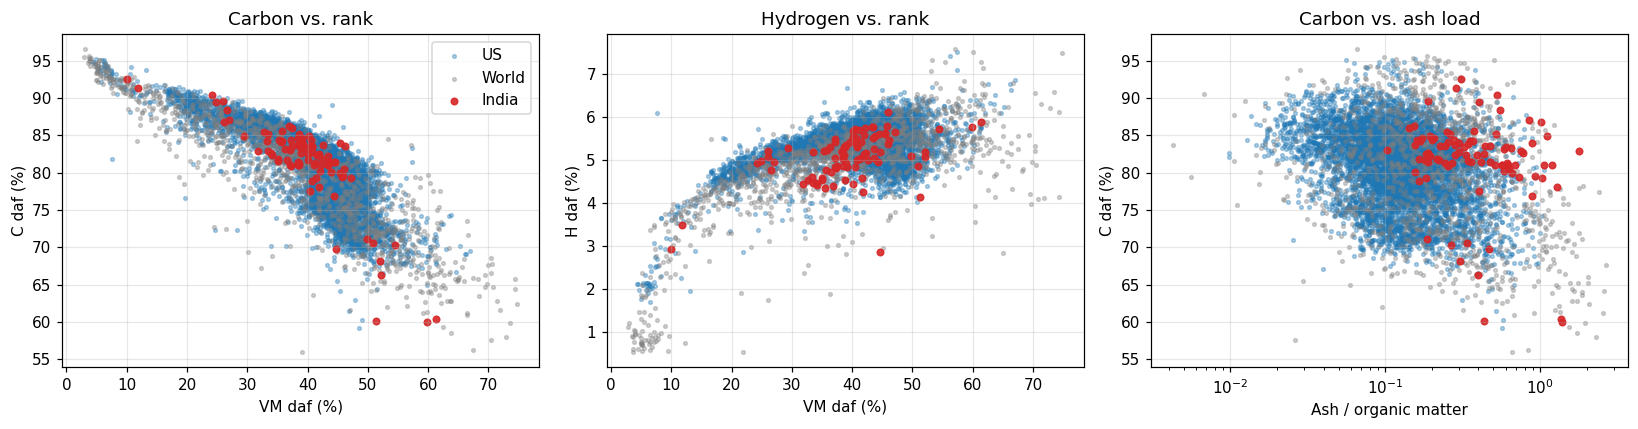

In [4]:
def features(d, use_moisture=True):
    org = 100 - d.M.values - d.Ash.values
    cols = [100 * d.VM.values / org, d.Ash.values / org] + ([d.M.values / org] if use_moisture else [])
    return np.column_stack(cols)

def targets(d):
    org = 100 - d.M.values - d.Ash.values
    return np.column_stack([100 * d[k].values / org for k in ["C", "H", "N", "S"]])

def to_ultimate(d, P_daf, s_measured=False):
    # C,H,N,S (daf) -> C,H,N,O,S on the input basis, oxygen by difference, exact closure
    org = 100 - d.M.values - d.Ash.values
    P = np.clip(P_daf, 0, None).copy()
    if s_measured:                      # use the lab sulphur instead of the predicted one
        P[:, 3] = 100 * d.S.values / org
        chn = P[:, :3].sum(axis=1)          # keep the measured S exactly if C+H+N+S would exceed 100
        over = chn + P[:, 3] > 100
        P[over, :3] *= ((100 - P[over, 3]) / chn[over])[:, None]
    O = np.clip(100 - P.sum(axis=1), 0, None)
    daf = np.column_stack([P[:, 0], P[:, 1], P[:, 2], O, P[:, 3]])
    daf = 100 * daf / daf.sum(axis=1, keepdims=True)
    return daf * org[:, None] / 100

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for name, d, c in [("US", us, "tab:blue"), ("World", world, "tab:gray"), ("India", ind, "tab:red")]:
    F, T = features(d), targets(d)
    kw = dict(s=6 if name != "India" else 18, alpha=0.35 if name != "India" else 0.9, c=c, label=name)
    ax[0].scatter(F[:, 0], T[:, 0], **kw); ax[1].scatter(F[:, 0], T[:, 1], **kw); ax[2].scatter(F[:, 1], T[:, 0], **kw)
ax[0].set(xlabel="VM daf (%)", ylabel="C daf (%)", title="Carbon vs. rank")
ax[1].set(xlabel="VM daf (%)", ylabel="H daf (%)", title="Hydrogen vs. rank")
ax[2].set(xlabel="Ash / organic matter", ylabel="C daf (%)", title="Carbon vs. ash load"); ax[2].set_xscale("log")
ax[0].legend(); plt.tight_layout(); plt.show()

## 3. Models

* **Linear** and **quadratic** regression (baselines; correlations of this type are common in the literature).
* **Gradient boosting** (histogram-based, one model per target).
* **Neural network**: multilayer perceptron, inputs and outputs standardised, ReLU activation, Adam optimiser, L2 regularisation (`alpha`), early stopping on a 10 % validation split.
* **Neural-network ensemble** (final model): several identical networks trained from different random initialisations, predictions averaged — averaging removes much of the run-to-run noise of single networks — and blended 70 : 30 with the quadratic regression, which extrapolates more smoothly for the small, high-ash Indian set.

Indian samples are few (91 vs ~6,460 US), so each Indian training row is repeated `K_INDIA` times; this tells the networks that Indian coal matters as much as the large US set. The hyper-parameters below were chosen in a separate grid search (hidden layers 32×32 … 128×64×32, alpha 1e-4 … 1e-1, K = 1 … 30, ensemble size, quadratic blend 0 / 0.3 / 0.5, with and without moisture, with and without the world data), using the same validation as section 4. Adding the World Coal Quality Inventory to the training data made Indian predictions *worse* (carbon MAE 1.60 vs 1.47 pp; that inventory mixes many laboratories and standards) and improved predictions for unseen countries only marginally (1.37 vs 1.44 pp), so it is kept out of training and used as an external test set instead.

In [5]:
HIDDEN   = (32, 32)   # hidden layers of each network
ALPHA    = 1e-2      # L2 regularisation
N_BAG    = 10         # networks in the ensemble
K_INDIA  = 30        # repetition of Indian rows in training
USE_WORLD = False    # include the World Coal Quality Inventory
POLY_W   = 0.3       # weight of the quadratic model blended into the ensemble (0 = pure neural network)


class NNEnsemble:
    # Ensemble of MLPs on the daf features; optional blend with a quadratic regression
    def __init__(self, hidden=HIDDEN, alpha=ALPHA, n=N_BAG, use_moisture=True, poly_w=POLY_W):
        self.hidden, self.alpha, self.n, self.use_m, self.poly_w = hidden, alpha, n, use_moisture, poly_w
    def fit(self, d):
        X, Y = features(d, self.use_m), targets(d)
        self.xs, self.ys = StandardScaler().fit(X), StandardScaler().fit(Y)
        Xs, Ys = self.xs.transform(X), self.ys.transform(Y)
        self.nets = [MLPRegressor(hidden_layer_sizes=self.hidden, alpha=self.alpha, learning_rate_init=1e-3,
                                  max_iter=2000, early_stopping=True, validation_fraction=0.1,
                                  n_iter_no_change=40, random_state=SEED + i).fit(Xs, Ys) for i in range(self.n)]
        self.poly = None
        if self.poly_w > 0:
            self.poly = LinearRegression().fit(PolynomialFeatures(2).fit_transform(Xs), Y)
        return self
    def predict_daf(self, d):
        Xs = self.xs.transform(features(d, self.use_m))
        p = self.ys.inverse_transform(np.mean([m.predict(Xs) for m in self.nets], axis=0))
        if self.poly is not None:
            p = (1 - self.poly_w) * p + self.poly_w * self.poly.predict(PolynomialFeatures(2).fit_transform(Xs))
        return p

class SkModel:
    def __init__(self, kind): self.kind = kind
    def fit(self, d):
        if self.kind == "Linear":
            self.m = make_pipeline(StandardScaler(), LinearRegression())
        elif self.kind == "Quadratic":
            self.m = make_pipeline(StandardScaler(), PolynomialFeatures(2), LinearRegression())
        else:
            self.m = MultiOutputRegressor(HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05,
                                          min_samples_leaf=20, l2_regularization=1.0, random_state=SEED))
        self.m.fit(features(d), targets(d)); return self
    def predict_daf(self, d): return self.m.predict(features(d))

MODELS = {
    "Linear regression": lambda: SkModel("Linear"),
    "Quadratic regression": lambda: SkModel("Quadratic"),
    "Gradient boosting": lambda: SkModel("GB"),
    "Single neural network": lambda: NNEnsemble(n=1, poly_w=0.0),
    f"Neural-network ensemble ({N_BAG} nets)": lambda: NNEnsemble(poly_w=0.0),
    f"FINAL: NN ensemble + {POLY_W:.0%} quadratic": lambda: NNEnsemble(),
    "FINAL without moisture input": lambda: NNEnsemble(use_moisture=False),
}
FINAL = f"FINAL: NN ensemble + {POLY_W:.0%} quadratic"

def training_set(us_part, ind_part):
    return pd.concat([us_part] + ([world] if USE_WORLD else []) + [ind_part] * K_INDIA, ignore_index=True)

## 4. Validation on coal the model has never seen

* **India — leave-one-site-out:** the 91 Indian samples come from 7 mines/blocks. Each site is removed in turn, the model is trained on everything else (all US + the other 6 Indian sites) and then predicts the removed site. This is a much harder and more honest test than a random split, because samples from the same seam are very similar.
* **US — grouped 5-fold:** sample groups (projects/batches) are held out together.

Metrics: mean absolute error (MAE) in **percentage points** (pp) — the plain difference between the predicted and measured wt % — plus RMSE and R².

In [6]:
ind_folds = list(LeaveOneGroupOut().split(ind, groups=ind.group))
us_folds = list(GroupKFold(5).split(us, groups=us.group))

def run_fold(name, which, tr, te):
    if which == "India":
        d, test = training_set(us, ind.iloc[tr]), ind.iloc[te]
    else:
        d, test = training_set(us.iloc[tr], ind), us.iloc[te]
    return te, MODELS[name]().fit(d).predict_daf(test)

t0 = time.time()
jobs = [(n, w, tr, te) for n in MODELS for w, folds in (("India", ind_folds), ("US", us_folds)) for tr, te in folds]
outs = Parallel(n_jobs=-1)(delayed(run_fold)(*j) for j in jobs)
CV = {}
for (n, w, tr, te), (te_, p) in zip(jobs, outs):
    CV.setdefault((n, w), np.zeros((len(ind) if w == "India" else len(us), 4)))[te] = p
print(f"cross-validation finished in {time.time() - t0:.0f} s ({len(jobs)} model fits)")

def metrics(d, P_daf, s_measured=False):
    pred, true = to_ultimate(d, P_daf, s_measured), d[ULT].values
    out = {}
    for j, k in enumerate(ULT):
        if s_measured and k == "S":
            continue
        e = pred[:, j] - true[:, j]
        out[k] = dict(MAE=np.abs(e).mean(), RMSE=np.sqrt((e ** 2).mean()), R2=r2_score(true[:, j], pred[:, j]))
    return out

rows = []
for n in MODELS:
    for w, d in (("India", ind), ("US", us)):
        m = metrics(d, CV[(n, w)])
        rows.append({"Model": n, "Test set": w, **{k: m[k]["MAE"] for k in ULT},
                     "Mean (C,H,N,O)": np.mean([m[k]["MAE"] for k in "CHNO"])})
mae = pd.DataFrame(rows)
print("Mean absolute error (percentage points) on held-out data")
mae.set_index(["Test set", "Model"]).sort_index().round(3)

cross-validation finished in 482 s (84 model fits)
Mean absolute error (percentage points) on held-out data


C      H      N      O      S  Mean (C,H,N,O)
Test set Model                                                                                
India    FINAL without moisture input        1.667  0.254  0.078  1.246  1.020           0.811
         FINAL: NN ensemble + 30% quadratic  1.371  0.197  0.088  1.012  1.156           0.667
         Gradient boosting                   1.739  0.248  0.092  1.257  1.197           0.834
         Linear regression                   1.125  0.222  0.095  1.088  1.360           0.632
         Neural-network ensemble (10 nets)   1.488  0.207  0.089  1.010  1.150           0.699
         Quadratic regression                1.162  0.211  0.092  1.077  1.227           0.635
         Single neural network               1.400  0.228  0.096  1.065  1.245           0.697
US       FINAL without moisture input        1.713  0.217  0.159  2.335  1.113           1.106
         FINAL: NN ensemble + 30% quadratic  0.999  0.145  0.151  1.131  0.957           0.606
         Gradient boosting                   0.976  0.145  0.156  1.132  0.954           0.602
         Linear regression                   1.251  0.189  0.163  1.641  1.272           0.811
         Neural-network ensemble (10 nets)   0.992  0.145  0.151  1.117  0.945           0.601
         Quadratic regression                1.075  0.155  0.158  1.255  1.118           0.661
         Single neural network               1.018  0.150  0.153  1.131  0.976           0.613

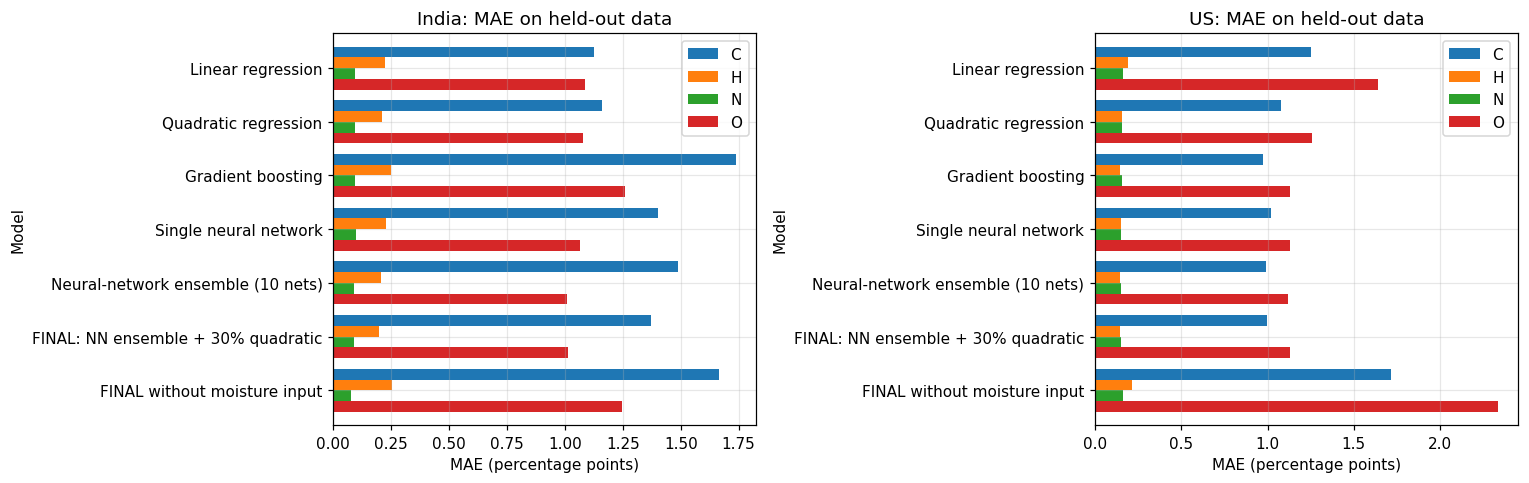

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, w in zip(ax, ["India", "US"]):
    t = mae[mae["Test set"] == w].set_index("Model")[["C", "H", "N", "O"]]
    t.plot.barh(ax=a, width=0.8)
    a.set(title=f"{w}: MAE on held-out data", xlabel="MAE (percentage points)"); a.invert_yaxis()
plt.tight_layout(); plt.show()

### 4.1 Detailed accuracy of the final model

In [8]:
detail = []
for w, d in (("India (leave-one-site-out)", ind), ("US (grouped 5-fold)", us)):
    key = "India" if w.startswith("India") else "US"
    for sm, lab in ((False, "S predicted"), (True, "S measured & given")):
        for k, v in metrics(d, CV[(FINAL, key)], sm).items():
            detail.append({"Test set": w, "Sulphur": lab, "Element": k, **v})
detail = pd.DataFrame(detail)
detail.pivot_table(index=["Test set", "Sulphur"], columns="Element", values=["MAE", "RMSE", "R2"]).round(3)

MAE                                 R2                               RMSE                            
Element                                            C      H      N      O      S      C      H      N      O      S      C      H      N      O      S
Test set                   Sulphur                                                                                                                    
India (leave-one-site-out) S measured & given  1.345  0.195  0.087  1.297    NaN  0.982  0.840  0.765  0.136    NaN  1.650  0.272  0.135  1.624    NaN
                           S predicted         1.371  0.197  0.088  1.012  1.156  0.980  0.837  0.765  0.297 -0.284  1.713  0.275  0.135  1.465  1.933
US (grouped 5-fold)        S measured & given  0.982  0.145  0.151  1.036    NaN  0.988  0.933  0.641  0.785    NaN  1.342  0.200  0.198  1.425    NaN
                           S predicted         0.999  0.145  0.151  1.131  0.957  0.987  0.932  0.639  0.751  0.297  1.393  0.201  0.198  1.532  1.479

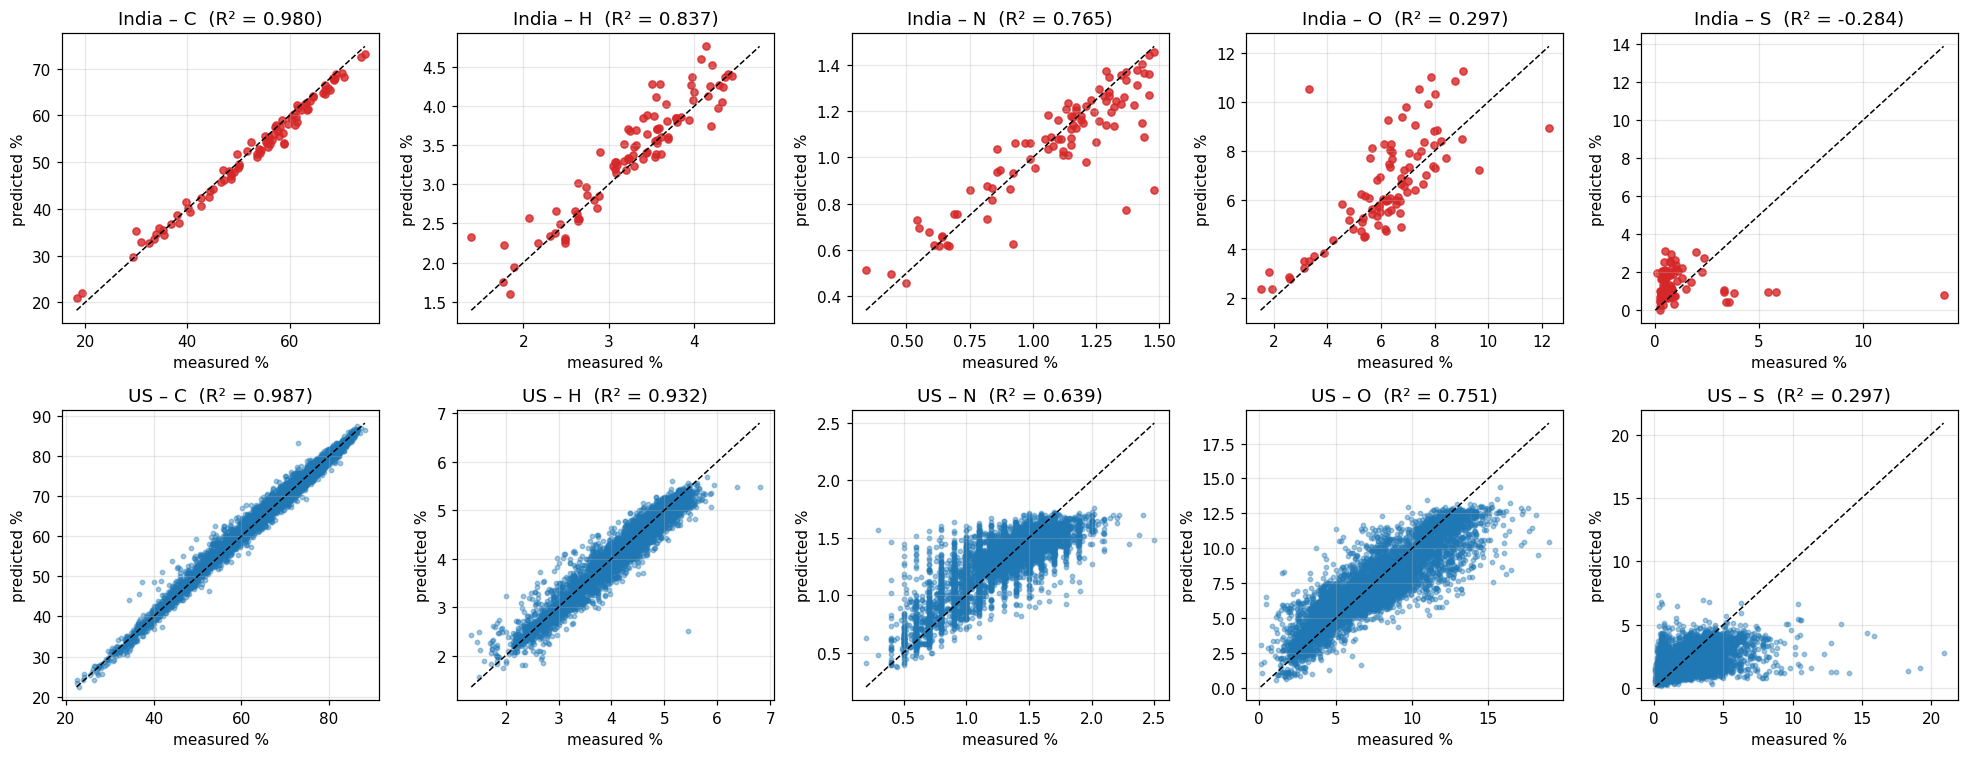

In [9]:
fig, ax = plt.subplots(2, 5, figsize=(18, 7))
for r, (w, d) in enumerate((("India", ind), ("US", us))):
    pred = to_ultimate(d, CV[(FINAL, w)])
    for j, k in enumerate(ULT):
        a = ax[r, j]; t = d[k].values
        a.scatter(t, pred[:, j], s=8 if w == "US" else 22, alpha=0.4 if w == "US" else 0.8,
                  c="tab:blue" if w == "US" else "tab:red")
        lo, hi = min(t.min(), pred[:, j].min()), max(t.max(), pred[:, j].max())
        a.plot([lo, hi], [lo, hi], "k--", lw=1)
        a.set(title=f"{w} – {k}  (R² = {r2_score(t, pred[:, j]):.3f})", xlabel="measured %", ylabel="predicted %")
plt.tight_layout(); plt.show()

**Reading the results**
* **Carbon** — the largest element — is predicted to within about 1–2 pp, **hydrogen** and **nitrogen** within ~0.1–0.2 pp, with R² close to 1 for carbon on both test sets.
* **Oxygen** is obtained by difference, so it collects the errors of the other elements; still ~1 pp.
* **Sulphur cannot be predicted** from a proximate analysis: it depends on pyrite and the depositional environment (marine vs. fresh-water), which leave no trace in M, VM, ash or FC. Its R² is low on every model. The app therefore lets the user enter a measured sulphur value (total sulphur is a routine test: IS 1350 Part 3 / ASTM D4239). That removes the sulphur error and lowers the total error over all five elements. For the Indian set the oxygen error alone rises somewhat, mostly in the pyrite-rich Giral lignite. There, ash (rather than true mineral matter) in the by-difference calculation distorts oxygen, and the predicted-S version happens to offset part of that.
* Removing the moisture input makes the US results much worse — moisture carries rank information for low-rank coals. For dry-basis data the app asks for the moisture of the original sample, and falls back to the no-moisture model only if it is unknown.

### 4.2 External test: 60 countries the model has never seen
The World Coal Quality Inventory is not used for training. A model trained on all US + Indian data predicts every one of its samples — coals from China, Indonesia, South Africa, Brazil, Europe and elsewhere, analysed in many different laboratories. The Gondwana subset (southern Africa, Brazil, Australia…) is geologically closest to Indian coal.

In [10]:
ext_model = NNEnsemble().fit(training_set(us, ind))
gond = world.Gondwana.values.astype(bool)
ext_rows = []
for lab, m in (("all 60 countries", np.ones(len(world), bool)), ("Gondwana coals", gond)):
    d = world[m]
    res = metrics(d, ext_model.predict_daf(d))
    ext_rows.append({"External test set": lab, "n": int(m.sum()), **{k: res[k]["MAE"] for k in ULT}})
print("MAE (percentage points), World Coal Quality Inventory, never used in training")
EXT = pd.DataFrame(ext_rows); EXT.round(3)

MAE (percentage points), World Coal Quality Inventory, never used in training


,External test set,n,C,H,N,O,S
0,all 60 countries,1239,1.450,0.29,0.226,1.672,1.186
1,Gondwana coals,103,2.563,0.39,0.168,2.584,2.229


## 5. Final model: train on all data and export

The final ensemble is trained on all US + Indian samples. Its weights are written to `model/coal_model.json` as plain numbers, so the web app needs only `numpy` (no pickled scikit-learn objects, which break between library versions). A second, smaller ensemble without the moisture input is exported for dry-basis inputs. Finally the exported JSON is re-loaded and checked against scikit-learn's own predictions.

In [11]:
full = training_set(us, ind)
t0 = time.time()
final = NNEnsemble().fit(full)
final_nom = NNEnsemble(use_moisture=False).fit(full)
print(f"trained on {len(full)} rows ({len(us)} US + {len(world) if USE_WORLD else 0} world + {len(ind)} India x {K_INDIA})"
      f" in {time.time() - t0:.0f} s")

def export(m, feats):
    spec = {"features": feats, "x_mean": m.xs.mean_.tolist(), "x_scale": m.xs.scale_.tolist(),
            "y_mean": m.ys.mean_.tolist(), "y_scale": m.ys.scale_.tolist(), "targets": ["C_daf", "H_daf", "N_daf", "S_daf"],
            "mlps": [{"W": [w.tolist() for w in n.coefs_], "b": [b.tolist() for b in n.intercepts_]} for n in m.nets]}
    if m.poly is not None:
        spec["poly"] = {"coef": m.poly.coef_.tolist(), "intercept": m.poly.intercept_.tolist(), "weight": m.poly_w}
    return spec

F_all = features(full)
fm = mae[mae.Model == FINAL].set_index("Test set")
meta = {
    "name": "Coal proximate -> ultimate neural-network ensemble", "version": "3.0",
    "trained": time.strftime("%Y-%m-%d"), "sklearn_version": sklearn.__version__,
    "hidden": list(HIDDEN), "alpha": ALPHA, "n_mlps": N_BAG, "k_india": K_INDIA,
    "models": {"with_moisture": export(final, ["VM_daf", "Ash/Org", "M/Org"]),
               "no_moisture": export(final_nom, ["VM_daf", "Ash/Org"])},
    "ranges": {"VMdaf": [float(F_all[:, 0].min()), float(F_all[:, 0].max())],
               "A_org": [float(F_all[:, 1].min()), float(F_all[:, 1].max())],
               "M_org": [float(F_all[:, 2].min()), float(F_all[:, 2].max())]},
    "accuracy": {
        "india_mae": {k: round(float(fm.loc["India", k]), 3) for k in ULT},
        "us_mae": {k: round(float(fm.loc["US", k]), 3) for k in ULT},
        "table": [{"Test set": ("India — unseen mines" if w == "India" else "US — unseen groups"),
                   **{k: round(float(fm.loc[w, k]), 3) for k in ULT}} for w in ("India", "US")]
                 + [{"Test set": "World, 60 unseen countries", **{k: round(float(EXT.iloc[0][k]), 3) for k in ULT}}]},
    "data": [{"Dataset": "USGS COALQUAL (US)", "Samples": len(us)},
             {"Dataset": "USGS–GSI India (Sohagpur, Giral) — weighted x%d" % K_INDIA, "Samples": len(ind)},
             {"Dataset": "USGS World Coal Quality Inventory (external test only)", "Samples": len(world)}],
}
os.makedirs(MODEL_DIR, exist_ok=True)
with open(os.path.join(MODEL_DIR, "coal_model.json"), "w") as f:
    json.dump(meta, f)
print("saved", os.path.join(MODEL_DIR, "coal_model.json"), f"({os.path.getsize(os.path.join(MODEL_DIR, 'coal_model.json')) / 1024:.0f} kB)")

trained on 9193 rows (6463 US + 0 world + 91 India x 30) in 465 s
saved model\coal_model.json (534 kB)


In [12]:
# Verify: the exported weights (pure numpy forward pass) reproduce scikit-learn's predictions exactly
def numpy_forward(spec, F):
    Xs = (F - np.array(spec["x_mean"])) / np.array(spec["x_scale"])
    outs = []
    for m in spec["mlps"]:
        h = Xs
        for i, (W, b) in enumerate(zip(m["W"], m["b"])):
            h = h @ np.array(W) + np.array(b)
            if i < len(m["W"]) - 1:
                h = np.maximum(h, 0)
        outs.append(h)
    p = np.mean(outs, axis=0) * np.array(spec["y_scale"]) + np.array(spec["y_mean"])
    if "poly" in spec:
        q = PolynomialFeatures(2).fit_transform(Xs) @ np.array(spec["poly"]["coef"]).T + np.array(spec["poly"]["intercept"])
        p = (1 - spec["poly"]["weight"]) * p + spec["poly"]["weight"] * q
    return p

with open(os.path.join(MODEL_DIR, "coal_model.json")) as f:
    loaded = json.load(f)
for key, m, use_m in (("with_moisture", final, True), ("no_moisture", final_nom, False)):
    diff = np.abs(numpy_forward(loaded["models"][key], features(full, use_m)) - m.predict_daf(full)).max()
    print(f"{key:14s} max |numpy - sklearn| = {diff:.2e}")
    assert diff < 1e-8

with_moisture  max |numpy - sklearn| = 0.00e+00
no_moisture    max |numpy - sklearn| = 0.00e+00


## 6. Using the model

`predict_ultimate()` takes a proximate analysis on **any** basis (as-received, air-dried or dry) and returns the ultimate analysis on the same basis, plus dry and dry-ash-free values. Indian laboratories normally report proximate analysis on the **air-dried basis (IS 1350 Part 1)**; US data are normally **as-received (ASTM D3172/D3176)** — both work directly.

In [13]:
def predict_ultimate(M, VM, Ash, S=None, model=final):
    d = pd.DataFrame({"M": [M], "VM": [VM], "Ash": [Ash], "S": [np.nan if S is None else S]})
    if M + VM + Ash > 100:
        raise ValueError("M + VM + Ash must not exceed 100 %")
    out = to_ultimate(d, model.predict_daf(d), s_measured=S is not None)[0]
    org = 100 - M - Ash
    return pd.DataFrame({"same basis (%)": out, "dry basis (%)": out * 100 / (100 - M),
                         "daf basis (%)": out * 100 / org}, index=ULT).round(2)

examples = {
    "Indian non-coking coal, high ash (air-dried)": dict(M=6.0, VM=24.0, Ash=35.0),
    "Indian coking coal, washed (air-dried)": dict(M=1.2, VM=24.0, Ash=17.0),
    "Indian lignite (as-received)": dict(M=35.0, VM=28.0, Ash=10.0),
    "US Appalachian bituminous (as-received)": dict(M=2.5, VM=33.0, Ash=9.0),
    "US Powder River Basin sub-bituminous (as-received)": dict(M=27.0, VM=31.0, Ash=5.5),
}
for name, x in examples.items():
    print(f"\n{name}:  M={x['M']}  VM={x['VM']}  Ash={x['Ash']}  FC={100 - sum(x.values()):.1f}")
    print(predict_ultimate(**x).T.to_string())


Indian non-coking coal, high ash (air-dried):  M=6.0  VM=24.0  Ash=35.0  FC=35.0
                    C     H     N      O     S
same basis (%)  47.77  3.04  1.00   6.51  0.68
dry basis (%)   50.82  3.23  1.07   6.93  0.72
daf basis (%)   80.96  5.15  1.70  11.04  1.15

Indian coking coal, washed (air-dried):  M=1.2  VM=24.0  Ash=17.0  FC=57.8
                    C     H     N     O     S
same basis (%)  70.91  4.24  1.26  3.56  1.83
dry basis (%)   71.77  4.29  1.28  3.60  1.86
daf basis (%)   86.69  5.18  1.54  4.35  2.24

Indian lignite (as-received):  M=35.0  VM=28.0  Ash=10.0  FC=27.0
                    C     H     N      O     S
same basis (%)  39.15  2.82  0.71  10.92  1.41
dry basis (%)   60.23  4.33  1.09  16.79  2.16
daf basis (%)   71.19  5.12  1.29  19.85  2.56

US Appalachian bituminous (as-received):  M=2.5  VM=33.0  Ash=9.0  FC=55.5
                    C     H     N     O     S
same basis (%)  74.78  4.85  1.48  6.00  1.39
dry basis (%)   76.70  4.97  1.52  6.15  1.43
d

In [14]:
# Sanity check on real Indian samples (these were in the final training set; the honest unseen-site errors are in section 4)
s = ind.sample(6, random_state=1)
p = to_ultimate(s, final.predict_daf(s))
cmp = s[["Sample ID", "M", "VM", "Ash"] + ULT].copy()
for j, k in enumerate(ULT):
    cmp["pred_" + k] = p[:, j].round(2)
cmp

,Sample ID,M,VM,Ash,C,H,N,O,S,pred_C,pred_H,pred_N,pred_O,pred_S
58,SKM-5-5,10.86,26.40,18.17,57.43,3.43,1.24,8.44,0.44,57.87,3.41,1.21,7.85,0.63
88,GR-VII-98-B,34.01,26.36,15.34,34.54,2.63,0.64,7.41,5.43,34.99,2.62,0.65,8.50,3.89
43,SBT-23-4,2.65,26.01,37.43,48.58,3.30,1.15,6.20,0.69,48.32,3.34,1.05,6.23,0.97
55,SDA-3,5.57,22.95,25.45,58.13,3.18,1.19,6.07,0.41,57.60,3.28,1.16,6.14,0.79
73,SSL-1-7,6.56,31.25,13.36,67.50,4.29,1.37,6.41,0.51,66.19,4.20,1.37,7.55,0.77
86,GR-VI-98B,36.70,27.24,13.27,35.16,2.86,0.67,8.03,3.31,34.95,2.74,0.63,8.89,2.82


## 7. Conclusions

* A physics-guided neural-network ensemble (blended with a quadratic regression) predicts the ultimate analysis of coal from the proximate analysis with mean errors of roughly **1–2 pp for carbon, ~0.2 pp for hydrogen, ~0.1 pp for nitrogen and ~1 pp for oxygen** on coal sites that were *never* used in training, for both Indian and US coals (exact numbers in section 4). It carries over to 60 other countries that are entirely absent from training (section 4.2), with larger errors for the Gondwana coals of southern Africa, Brazil and Australia (about 2.5 pp for carbon). Different laboratories and the very inertinite-rich nature of those coals make them the hardest case.
* Working on the dry, ash-free basis is the key step: it makes data from different countries and different reporting bases compatible and enforces C + H + N + S + O + M + Ash = 100 %.
* On the large, diverse US set the neural networks clearly beat linear and quadratic correlations. On the small Indian set the simple correlations are marginally better (by about 0.03–0.04 pp on average), which is why the final model blends the network ensemble with a quadratic regression. It is the best compromise across both test sets, and averaging 10 networks makes it stable.
* **Limitations.** (1) Sulphur is not predictable from a proximate analysis — use a measured value when available. (2) The Indian training data cover the Sohagpur coalfield (Gondwana bituminous) and Rajasthan lignite; for other coalfields (e.g. high-sulphur north-eastern Tertiary coals) errors may be larger. (3) Ash is used as a proxy for mineral matter; for coals rich in carbonates or pyrite the volatile-matter correction is approximate. More open Indian data with both analyses would be the most valuable improvement.

**References.** Palmer, C.A., et al. (2015) *U.S. Geological Survey COALQUAL database version 3.0*, USGS Data Series 975. Tewalt, S.J., et al. (2010) *A digital compilation of world coal quality data* (WoCQI), USGS OFR 2010-1196. Trippi, M.H. & Tewalt, S.J. (2011) *Geographic information system of coal-quality data for India and Bangladesh*, USGS OFR 2011-1296. IS 1350 (Part 1): Methods of test for coal and coke — proximate analysis. ASTM D3172 / D3176.